**Libraries**

In [5]:
import sys
from pathlib import Path

cloned_rep_path=r'C:\Users\laika\OneDrive\Documents\Capstone I All Files\Capstone-DATA4381'
sys.path.insert(0,cloned_rep_path)

from capstone_data.image_loader import load_dataset

In [6]:
from collections import Counter
import pandas as pd
from sklearn.model_selection import train_test_split
import cv2
import numpy as np
import face_recognition
import matplotlib.pyplot as plt


c:\Users\laika\OneDrive\Documents\Capstone I All Files\.venv\Lib\site-packages\face_recognition_models\__init__.py:7: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_filename


**Load Clean Images**

In [7]:
# Image path
data_path=Path(r'C:\Users\laika\OneDrive\Documents\Capstone I All Files\MyWorkspaceLP\cleaned_data')
dataset=load_dataset(data_path)

print(f'Total images: {len(dataset)}')

classes=[i['class_name'] for i in dataset]
class_counts=Counter(classes)

# dataframe
df=(pd.DataFrame(dataset))
display(df.head(5))

Total images: 16779


,path,label,class_name
0,C:\Users\laika\OneDrive\Documents\Capstone I A...,0,angry
1,C:\Users\laika\OneDrive\Documents\Capstone I A...,0,angry
2,C:\Users\laika\OneDrive\Documents\Capstone I A...,0,angry
3,C:\Users\laika\OneDrive\Documents\Capstone I A...,0,angry
4,C:\Users\laika\OneDrive\Documents\Capstone I A...,0,angry


In [12]:
print(dataset[0])

{'path': WindowsPath('C:/Users/laika/OneDrive/Documents/Capstone I All Files/MyWorkspaceLP/cleaned_data/angry_clean/angry_cleaned_test/PrivateTest_10131363.jpg'), 'label': 0, 'class_name': 'angry'}


In [39]:
# remove neutral

df=df[df['class_name']!='neutral'].reset_index(drop=True)

classes=df['class_name'].value_counts().reset_index()
classes.columns=['Class', 'Count']
display(classes)

,Class,Count
0,happy,6677
1,angry,3089
2,sad,1207


**Split Dataset**

In [41]:


# First split (Isolate Test Set to 15%)

# Stratify--> to make sure categories are represnted in the same proportions as they were in the original dataset

train_val_df, test_df=train_test_split(
    df, test_size=0.15, random_state=42, stratify=df['class_name'].str.lower()
)


# Second Split (Divide Train and Validation)

train_df, val_df=train_test_split(
    train_val_df,
    test_size=0.15/0.85,
    random_state=42,
    stratify=train_val_df['class_name'].str.lower()
)

print(f'Train set: {len(train_df)}\nValidation set: {len(val_df)}\n Test set: {len(test_df)}')

Train set: 7681
Validation set: 1646
 Test set: 1646


**Extracting Facial Features (OpenCV and face_recognition)**

Uses HOG model by default to detect facial landmarks. Since HOG model was trained to look for faces that were at least 80x80 pixels, upscaling is needed. FER2013 images are 48x48.

link: https://face-recognition.readthedocs.io/en/latest/readme.html

Note: The face recognition model was trained on adults so it does not work well with children.

It converts it as color but it looks greyscale still.

[{'chin': [(67, 160), (73, 199), (82, 238), (93, 277), (107, 315), (127, 350), (152, 381), (182, 402), (222, 406), (264, 401), (297, 378), (323, 347), (344, 310), (354, 269), (359, 227), (363, 184), (363, 141)], 'left_eyebrow': [(73, 139), (92, 121), (120, 121), (148, 129), (175, 139)], 'right_eyebrow': [(209, 136), (240, 124), (273, 115), (306, 115), (332, 133)], 'nose_bridge': [(196, 162), (197, 189), (198, 215), (199, 243)], 'nose_tip': [(169, 253), (185, 259), (204, 265), (223, 257), (241, 249)], 'left_eye': [(107, 158), (122, 150), (142, 150), (162, 162), (141, 165), (122, 165)], 'right_eye': [(240, 159), (257, 147), (277, 146), (296, 152), (280, 160), (260, 161)], 'top_lip': [(158, 304), (169, 284), (189, 278), (209, 282), (229, 276), (253, 279), (272, 298), (266, 298), (230, 288), (211, 291), (191, 290), (165, 303)], 'bottom_lip': [(272, 298), (258, 329), (237, 344), (215, 347), (194, 345), (172, 331), (158, 304), (165, 303), (192, 325), (213, 328), (233, 324), (266, 298)]}]


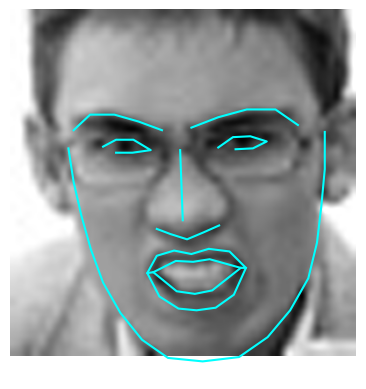

In [57]:
# Test on one image
image=face_recognition.load_image_file(r'C:\Users\laika\OneDrive\Documents\Capstone I All Files\MyWorkspaceLP\cleaned_data\angry_clean\angry_cleaned_train\Training_345125.jpg')

# Upscale image (Use interpolation to smooth out image)
upscale_image=cv2.resize(image, (400,400), interpolation=cv2.INTER_CUBIC)


# Get locations and outlines of face
face_landmarks=face_recognition.face_landmarks(upscale_image)

# Print face_landmarks (It is stored as a dictionary)
print(face_landmarks)
plt.imshow(upscale_image)


# Display facial landmarks
if face_landmarks:
    single_face=face_landmarks[0]
    for feature in single_face.keys():
        points=single_face[feature]
        
        # Grab x and y from the tuple list of points and but into 2 flat lists
        x=[i[0] for i in points]
        y=[i[1] for i in points]
        
        plt.plot(x,y, color='cyan')
plt.axis('off')
plt.show()

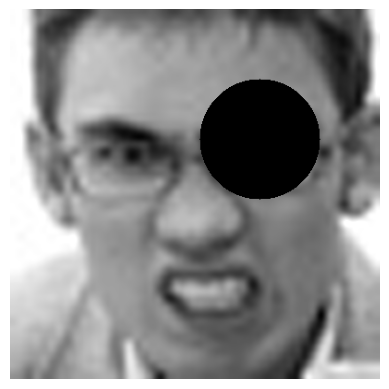

In [ ]:
# Black out right eye (Circle here but it will be rectangles in final augmented dataset)
image = face_recognition.load_image_file(r'C:\Users\laika\OneDrive\Documents\Capstone I All Files\MyWorkspaceLP\cleaned_data\angry_clean\angry_cleaned_train\Training_345125.jpg')
upscale_image = cv2.resize(image, (400, 400), interpolation=cv2.INTER_CUBIC)

if face_landmarks:
    single_face=face_landmarks[0]
    right_side=['right_eye', 'right_eyebrow']
    
    x=[]
    y=[]
    
    for i in right_side:
        if i in single_face:
            
            points=single_face[i]
            
            x.extend(j[0] for j in points)
            y.extend(j[1] for j in points)
            
            
    if x and y:
        
         x_center=int(sum(x)/len(x))
         y_center=int(sum(y)/len(y))
         radius=int(max(max(x)-min(x),max(y)-min(y))/2+4)
         
    cv2.circle(upscale_image, (x_center,y_center), radius, color=(0,0,0), thickness=-1)
         
        
plt.imshow(upscale_image)
plt.axis('off')
plt.show()